# NN_L12_rag_qa

**Which ECB board member gave the speech? Answers of Qwen2.5-3B-Instruct without documents, with the top-3 retrieved speeches (RAG) and with the right speech: share correct, wrong (hallucinated) and abstaining, speeches since 2025.**

Neural Networks and Deep Learning (NN), Lecture 12 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L12/NN_L12_rag_qa/NN_L12_rag_qa.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

closed: correct (%) = 13.8   [rag.qa_closed.correct]
closed_abstain: correct (%) = 0.0   [rag.qa_closed_abstain.correct]
rag: correct (%) = 81.2   [rag.qa_rag.correct]
oracle: correct (%) = 98.8   [rag.qa_oracle.correct]
closed: wrong (%) = 86.2   [rag.qa_closed.wrong]
closed_abstain: wrong (%) = 0.0   [rag.qa_closed_abstain.wrong]
rag: wrong (%) = 4.4   [rag.qa_rag.wrong]
oracle: wrong (%) = 0.0   [rag.qa_oracle.wrong]
closed: abstain (%) = 0.0   [rag.qa_closed.abstain]
closed_abstain: abstain (%) = 100.0   [rag.qa_closed_abstain.abstain]
rag: abstain (%) = 14.4   [rag.qa_rag.abstain]
oracle: abstain (%) = 1.2   [rag.qa_oracle.abstain]


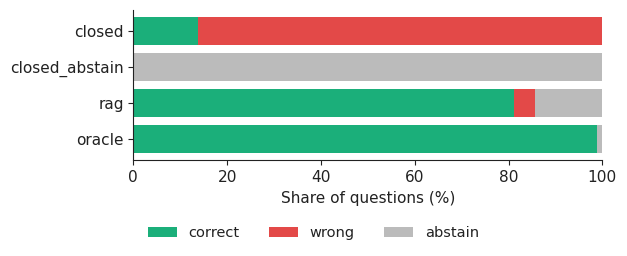

In [3]:
RES = REPO + 'lectures/L12/results/'
import json, urllib.request
def load_json(name):
    p = RES + name
    return json.load(open(p)) if os.path.exists(p) else json.load(urllib.request.urlopen(p))
Q = pd.read_csv(RES + 'rag_qa.csv')
modes = ['closed', 'closed_abstain', 'rag', 'oracle']
fig, ax = plt.subplots(figsize=(6.4, 2.6))
left = np.zeros(4)
for k, c in (('correct', PAL['benchmark']), ('wrong', PAL['positive']), ('abstain', '#bbbbbb')):
    v = np.array([round(100 * float((Q[m] == k).mean()), 1) for m in modes])
    for m, x in zip(modes, v):
        show(f'rag.qa_{m}.{k}', f'{m}: {k} (%)', float(x))
    ax.barh(range(4), v, left=left, color=c, label=k)
    left += v
ax.set_yticks(range(4))
ax.set_yticklabels(modes)
ax.invert_yaxis()
ax.set_xlabel('Share of questions (%)')
legend_bottom(fig, ncol=3)
fig.tight_layout(rect=(0, 0.12, 1, 1))
fig.savefig('rag_qa.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()